#### Important : All these statistics are before image and captions preprocessing (tockenization ,removal of stop words ...ect ) , but after ensuring data splits , min 5 captions per image , anti leackage rules


“object statistics are based on YOLO-World image detections, not COCO instance annotations”
“caption statistics remain from the caption corpus”

## Notebook Navigation Guide

1. Imports & Setup  
   - Load required libraries  
   - Set plotting style

2. Load COCO Annotations  
   - Load KB image IDs  
   - Load caption and instance annotations  
   - Filter data to KB images  
   - Print dataset counts

3. Object Class Distribution  
   - Top 50 Object Class Frequencies  
   - Most common object categories in the KB

4. Textual Statistics  
   - Part-of-Speech (POS) Distribution  
   - Vocabulary Size & Word Statistics Before caption preprocessing
   - Vocabulary Size & Word Statistics After caption preprocessing
   - bar plot for before vs after caption pre processing (Vocabulary size , avg caption legnth (Normalized))

5. Diversity Analysis  
   - Color frequency in captions  
   - Context keyword frequency in captions

6. Scene Complexity  
   - Objects per Image  (objects derived from images)
   - Spatial Relationships   (relationshipts derived from caption (nltk))
   - Visual Relationships frequency statistics (derived from images)

7. Data Visualization  
   - Object Co-Occurrence Matrix  
   - Caption Length Distribution  
   - Caption Length vs. Object Count per Image

8. Export Summary Statistics CSV  
   - Save summary metrics  
   - Display final table

# 1. Imports & Setup

In [22]:
import json
import os
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set clean styling for report-ready plots
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'figure.autolayout': True
})

print("Libraries loaded successfully!")

Libraries loaded successfully!


Load the COCO Annotations

# 2. filtering according to the 10000 ids that we have 

In [23]:
import json
import os

# 1. Load your team's frozen 10,000 Knowledge Base Image IDs
with open("../data/coco_rag_data/train_kb_ids.json", "r") as f:
    kb_data = json.load(f)
    kb_image_ids = list(kb_data) # Should be exactly 10,000 IDs

# 2. Load captions and the unified lookup used by the real pipeline
ANNOTATIONS_DIR = "../data/annotations_trainval2017/annotations"
with open(os.path.join(ANNOTATIONS_DIR, "captions_train2017.json"), 'r') as f:
    captions_data = json.load(f)

with open("../data/coco_rag_data/train_kb_lookup.json", "r", encoding="utf-8") as f:
    lookup = json.load(f)

## Build a dictionary mapping image IDs to their object counts
image_object_counts = {
    int(image_id_str): len(entry.get("objects", []))
    for image_id_str, entry in lookup.items()
    if int(image_id_str) in kb_image_ids
}

# 3. FILTER Captions to ONLY include your 10,000 KB images
filtered_captions = [
    ann for ann in captions_data['annotations']
    if ann['image_id'] in kb_image_ids
]

# 4. Build object stats from the actual lookup metadata used by the pipeline
object_counter = Counter()
for image_id_str, entry in lookup.items():
    image_id = int(image_id_str)
    if image_id in kb_image_ids:
        for obj in entry.get("objects", []):
            object_counter[obj] += 1

print(f"Total detected object entries in KB lookup: {sum(object_counter.values())}")

Total detected object entries in KB lookup: 20419


# 3. Distribution of object classes

### Top 50 Object Class Frequencies (COCO Categories)

/tmp/ipykernel_13067/3835505309.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts, y=names, palette="viridis")


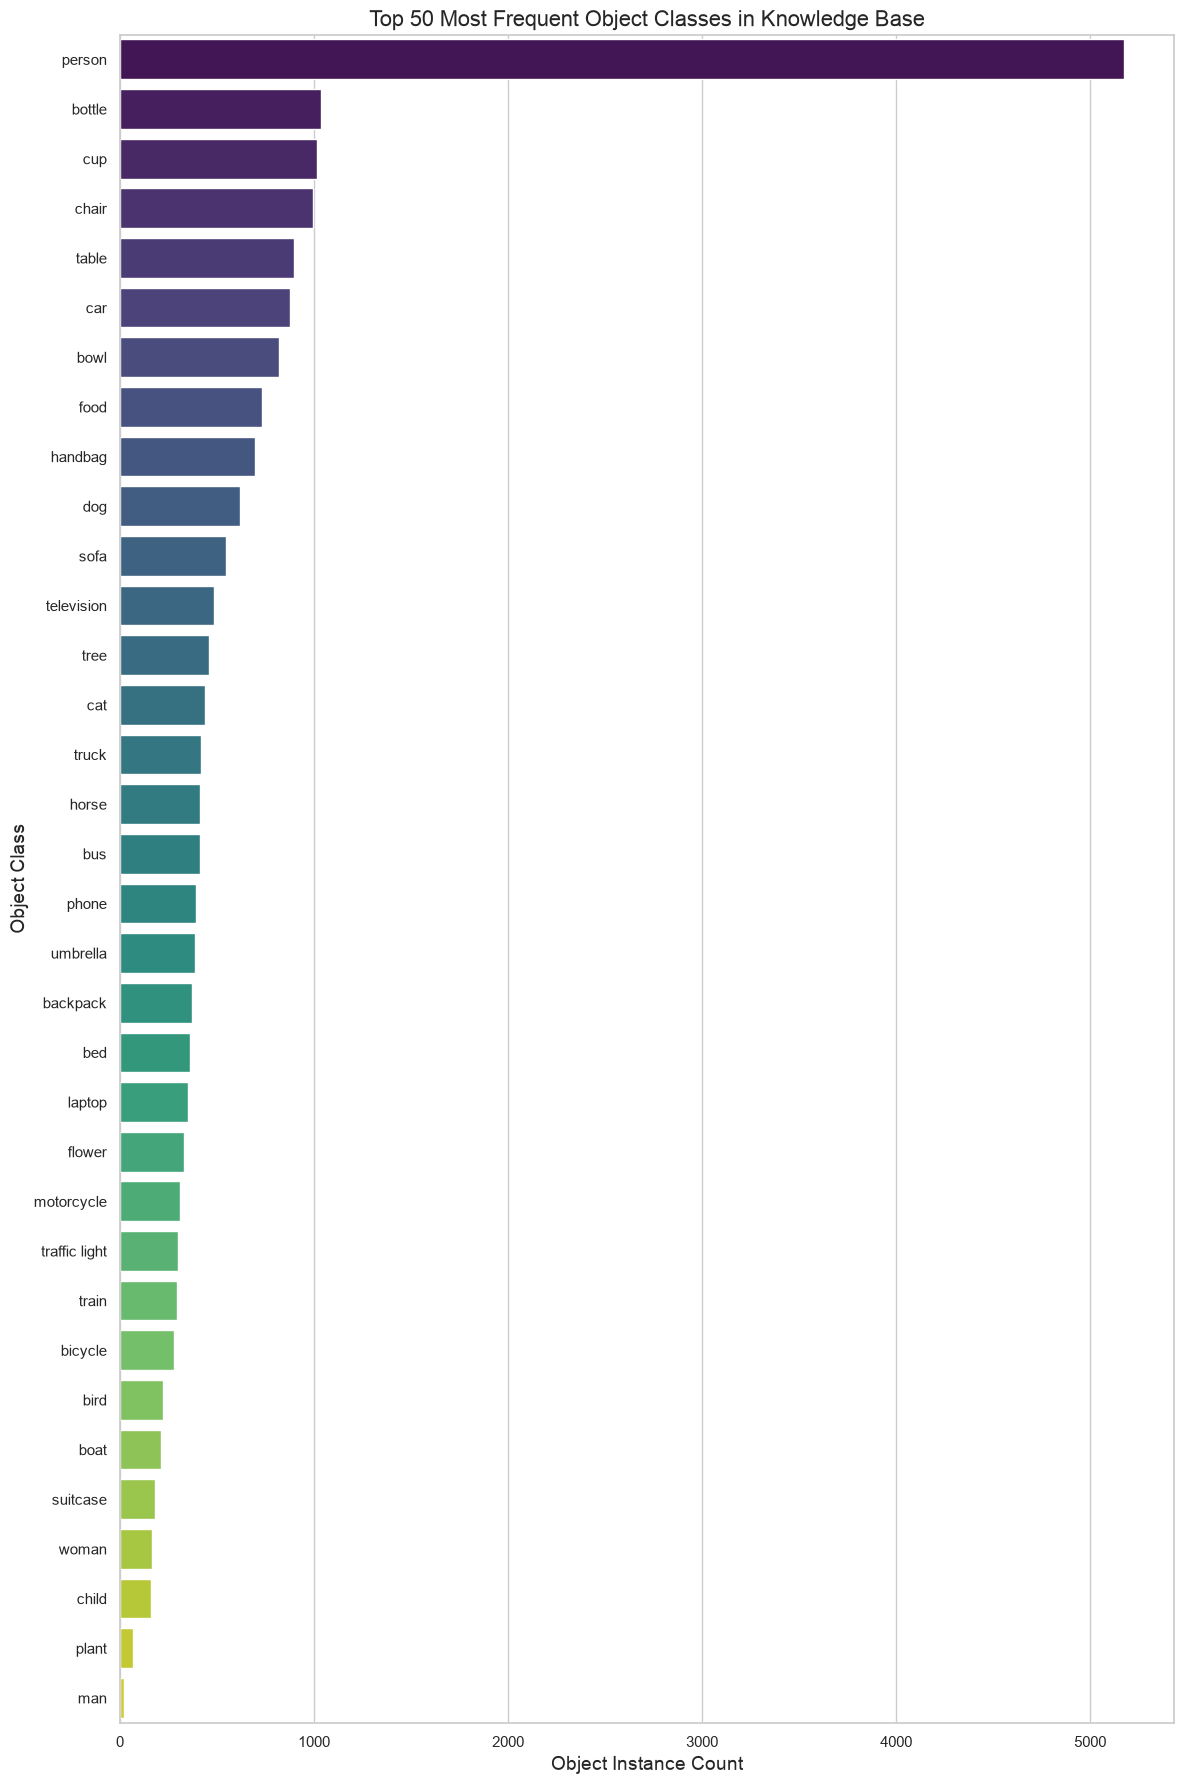

In [24]:
# Count object occurrences from the unified lookup
top_categories = object_counter.most_common(50)
names = [obj for obj, count in top_categories]
counts = [count for obj, count in top_categories]

# Plotting Top 50 Objects
plt.figure(figsize=(12, 18))
sns.barplot(x=counts, y=names, palette="viridis")
plt.title("Top 50 Most Frequent Object Classes in Knowledge Base")
plt.xlabel("Object Instance Count")
plt.ylabel("Object Class")
plt.savefig("top_objects_frequency.png", dpi=300)
plt.show()

# 4. Textual statistics

### Part-of-Speech (POS) Distribution

 Note : we only used 5000 just for computation and time purpose and it's choosen randomly so it's not gonna affect the overall distibution

[nltk_data] Downloading package punkt to /home/hz/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/hz/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /home/hz/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /home/hz/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package punkt_tab to /home/hz/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
/tmp/ipykernel_13067/4031527569.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(pos_count

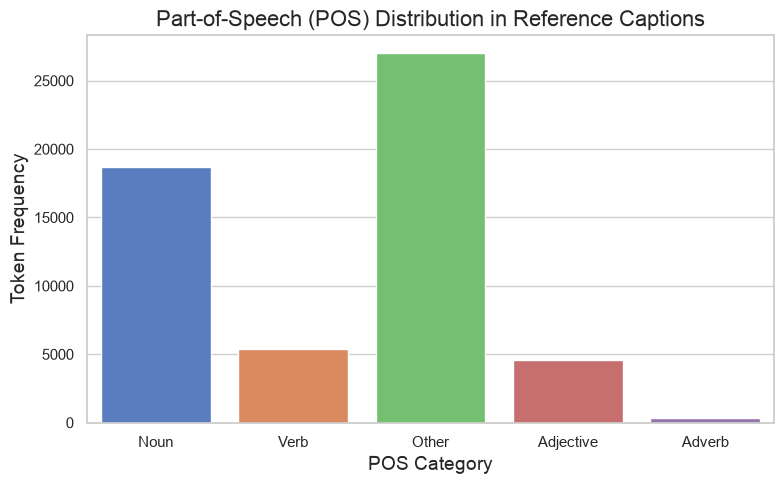

In [25]:
import nltk
from nltk import pos_tag

# Download POS tagger dictionary if not already present
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('punkt_tab')

# Sample a subset of captions (e.g., 5,000) for fast POS tagging computation
sample_captions = [ann['caption'] for ann in filtered_captions[:5000]]
pos_counts = Counter()

for cap in sample_captions:
    tokens = nltk.word_tokenize(cap)
    tags = pos_tag(tokens)
    for word, tag in tags:
        # Simplify tags to main categories (Noun, Verb, Adj, Adv, etc.)
        if tag.startswith('NN'): pos_counts['Noun'] += 1
        elif tag.startswith('VB'): pos_counts['Verb'] += 1
        elif tag.startswith('JJ'): pos_counts['Adjective'] += 1
        elif tag.startswith('RB'): pos_counts['Adverb'] += 1
        else: pos_counts['Other'] += 1

# Plot POS Distribution
plt.figure(figsize=(8, 5))
sns.barplot(x=list(pos_counts.keys()), y=list(pos_counts.values()), palette="muted")
plt.title("Part-of-Speech (POS) Distribution in Reference Captions")
plt.xlabel("POS Category")
plt.ylabel("Token Frequency")
plt.savefig("pos_distribution.png", dpi=300)
plt.show()

### Vocabulary Size & Word Statistics

In [26]:
from collections import Counter

# Tokenize all captions into words (lowercased for vocabulary counting)
all_words = []
for ann in filtered_captions:
    words = ann['caption'].lower().split()
    all_words.extend(words)

vocab_set = set(all_words)
print(f"Total word tokens: {len(all_words):,}")
print(f"Unique Vocabulary Size: {len(vocab_set):,}")

Total word tokens: 523,349
Unique Vocabulary Size: 13,658


### Vocabulary Size & Word Statistics After Preprocessing
This version measures the cleaned caption corpus after punctuation removal and lowercasing.

In [27]:
with open("../data/coco_rag_data/captions_kb.json", "r", encoding="utf-8") as f:
    caption_store = json.load(f)

processed_words = []
for image_id, entry in caption_store.items():
    if int(image_id) in kb_image_ids:
        for text in entry.get("caption_clean", []):
            processed_words.extend(text.split())

vocab_set_after = set(processed_words)

print(f"Total processed word tokens: {len(processed_words):,}")
print(f"Unique vocabulary size after preprocessing: {len(vocab_set_after):,}")

Total processed word tokens: 523,460
Unique vocabulary size after preprocessing: 9,630


### bar plot for before vs after caption pre processing (Vocabulary size , avg caption legnth (Normalized))

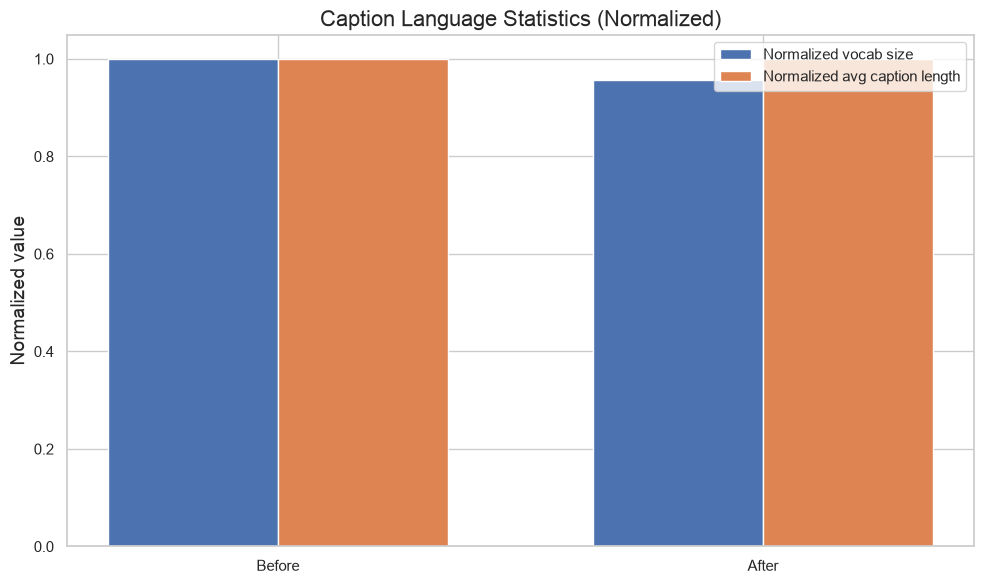

Before vocab: 10075, after vocab: 9630
Before avg len: 10.46, after avg len: 10.47


In [28]:
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

with open("../data/annotations_trainval2017/annotations/captions_train2017.json", "r", encoding="utf-8") as f:
    coco_caps = json.load(f)["annotations"]

with open("../data/coco_rag_data/captions_kb.json", "r", encoding="utf-8") as f:
    caption_store = json.load(f)

selected_ids = set(int(k) for k in caption_store.keys())

before_words = []
after_words = []
before_lengths = []
after_lengths = []

for ann in coco_caps:
    if ann["image_id"] in selected_ids:
        text = ann["caption"].lower().replace(".", "").replace(",", "")
        before_words.extend(text.split())
        before_lengths.append(len(text.split()))

for image_id, entry in caption_store.items():
    if int(image_id) in selected_ids:
        for cap in entry.get("caption_clean", []):
            text = cap.lower().replace(".", "").replace(",", "")
            after_words.extend(text.split())
            after_lengths.append(len(text.split()))

before_vocab = len(set(before_words))
after_vocab = len(set(after_words))

before_avg_len = np.mean(before_lengths)
after_avg_len = np.mean(after_lengths)

vocab_values = [before_vocab, after_vocab]
length_values = [before_avg_len, after_avg_len]

vocab_norm = [v / max(vocab_values) for v in vocab_values]
length_norm = [v / max(length_values) for v in length_values]

labels = ["Before", "After"]

plt.figure(figsize=(10, 6))
bar_width = 0.35

plt.bar(np.arange(len(labels)) - bar_width/2, vocab_norm, width=bar_width, color="#4C72B0", label="Normalized vocab size")
plt.bar(np.arange(len(labels)) + bar_width/2, length_norm, width=bar_width, color="#DD8452", label="Normalized avg caption length")

plt.xticks(np.arange(len(labels)), labels)
plt.title("Caption Language Statistics (Normalized)")
plt.ylabel("Normalized value")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Before vocab: {before_vocab}, after vocab: {after_vocab}")
print(f"Before avg len: {before_avg_len:.2f}, after avg len: {after_avg_len:.2f}")

# 5. Diversity analysis (Color , Context)

/tmp/ipykernel_13067/434404853.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(color_counts.keys()), y=list(color_counts.values()), palette="crest")


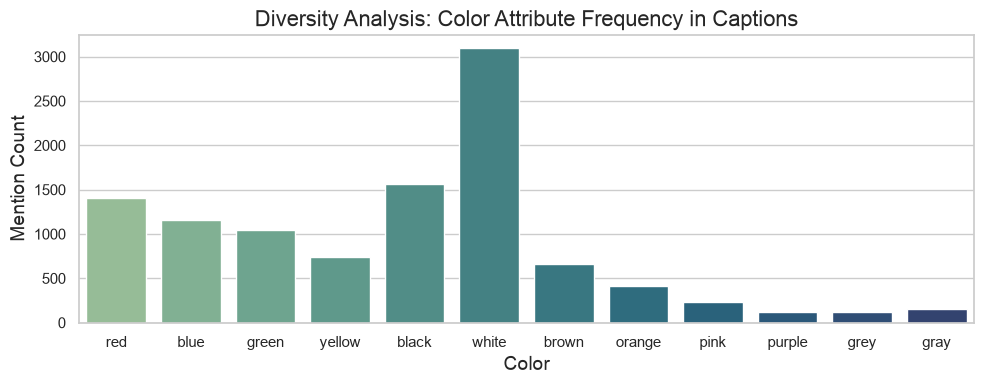

/tmp/ipykernel_13067/434404853.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(context_counts.keys()), y=list(context_counts.values()), palette="flare")


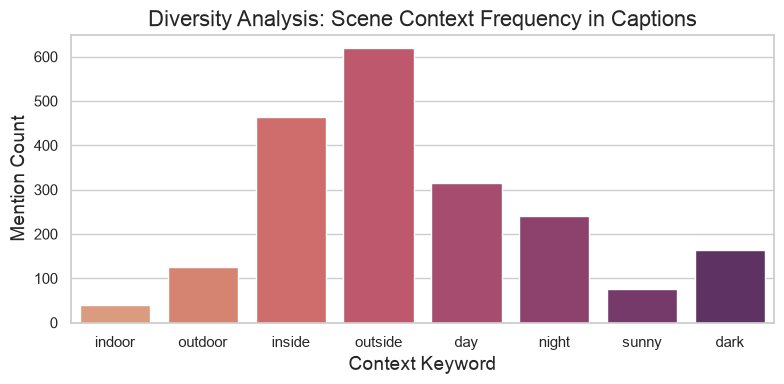

In [29]:
import re

# Define keyword dictionaries to search for in your 50,029 captions (USING NTLK WE ARE USING LANGUAGE 
## BASED COLOR AND CONTEXT KEYWORDS)
colors = ['red', 'blue', 'green', 'yellow', 'black', 'white', 'brown', 'orange', 'pink', 'purple', 'grey', 'gray']
contexts = ['indoor', 'outdoor', 'inside', 'outside', 'day', 'night', 'sunny', 'dark']

color_counts = {c: 0 for c in colors}
context_counts = {c: 0 for c in contexts}

for ann in filtered_captions:
    text = ann['caption'].lower()
    for color in colors:
        if re.search(r'\b' + color + r'\b', text):
            color_counts[color] += 1
    for ctx in contexts:
        if re.search(r'\b' + ctx + r'\b', text):
            context_counts[ctx] += 1

# Plot Color Diversity
plt.figure(figsize=(10, 4))
sns.barplot(x=list(color_counts.keys()), y=list(color_counts.values()), palette="crest")
plt.title("Diversity Analysis: Color Attribute Frequency in Captions")
plt.xlabel("Color")
plt.ylabel("Mention Count")
plt.savefig("color_diversity.png", dpi=300)
plt.show()

# Plot Context Diversity
plt.figure(figsize=(8, 4))
sns.barplot(x=list(context_counts.keys()), y=list(context_counts.values()), palette="flare")
plt.title("Diversity Analysis: Scene Context Frequency in Captions")
plt.xlabel("Context Keyword")
plt.ylabel("Mention Count")
plt.savefig("context_diversity.png", dpi=300)
plt.show()

# 6. Scene Complexity 

### Objects per Image

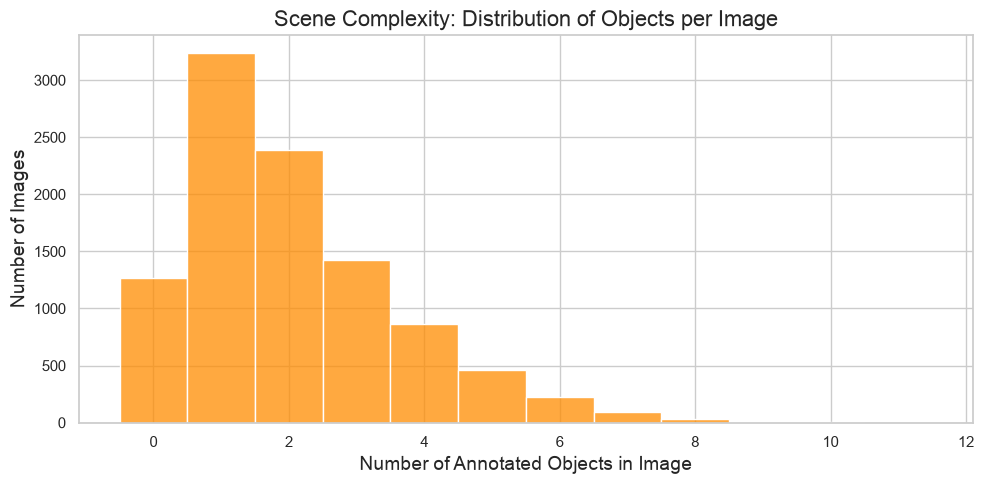

Average objects per image: 2.04


In [30]:
# Count how many objects appear in each image (WE ARE USING OBJECTS FROM IMAGES DIRECTLY)
objects_per_image_list = [
    len(entry.get("objects", []))
    for image_id_str, entry in lookup.items()
    if int(image_id_str) in kb_image_ids
]

# Plotting
plt.figure(figsize=(10, 5))
sns.histplot(objects_per_image_list, bins=range(1, 20), discrete=True, color='darkorange')
plt.title("Scene Complexity: Distribution of Objects per Image")
plt.xlabel("Number of Annotated Objects in Image")
plt.ylabel("Number of Images")
plt.savefig("scene_complexity.png", dpi=300)
plt.show()

print(f"Average objects per image: {sum(objects_per_image_list)/len(objects_per_image_list):.2f}")

### Spatial relationships.

/tmp/ipykernel_13067/2053443053.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(prep_counts.keys()), y=list(prep_counts.values()), palette="magma")


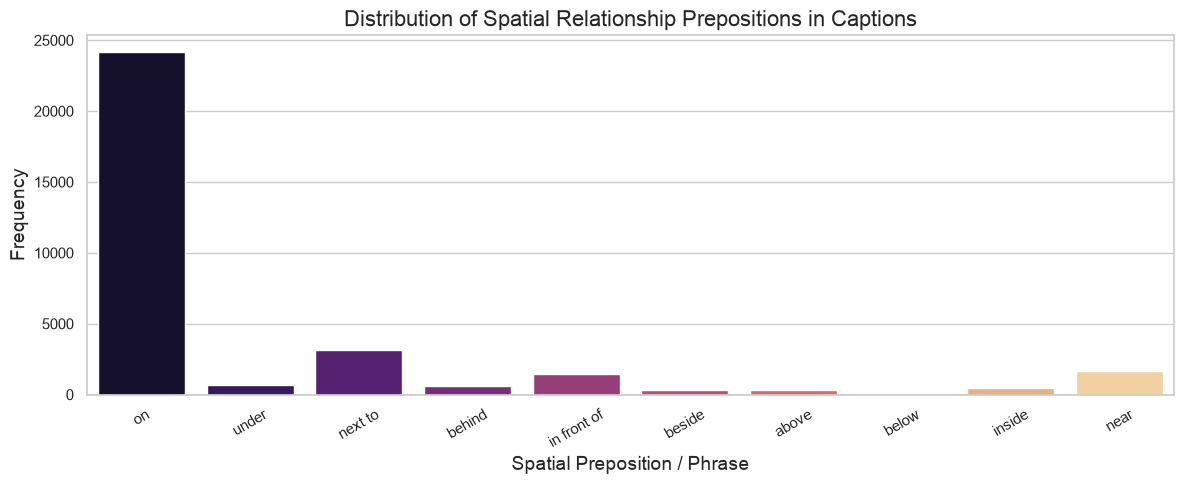

In [31]:
# Common spatial prepositions used to describe object layouts (EXTRACTED FROM CAPTIONS NOT IMAGES)
spatial_preps = ['on', 'under', 'next to', 'behind', 'in front of', 'beside', 'above', 'below', 'inside', 'near']
prep_counts = {p: 0 for p in spatial_preps}

for ann in filtered_captions:
    text = ann['caption'].lower()
    for prep in spatial_preps:
        # Check phrase match
        if prep in text:
            prep_counts[prep] += 1

# Plot Spatial Relationships
plt.figure(figsize=(12, 5))
sns.barplot(x=list(prep_counts.keys()), y=list(prep_counts.values()), palette="magma")
plt.title("Distribution of Spatial Relationship Prepositions in Captions")
plt.xlabel("Spatial Preposition / Phrase")
plt.ylabel("Frequency")
plt.xticks(rotation=30)
plt.savefig("spatial_relationships.png", dpi=300)
plt.show()

### Visual Relationship Analysis (Image-derived)
This section is not caption language analysis. It describes detector-generated relationships from the lookup metadata.

/tmp/ipykernel_13067/4027328088.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts, y=names, palette="magma")


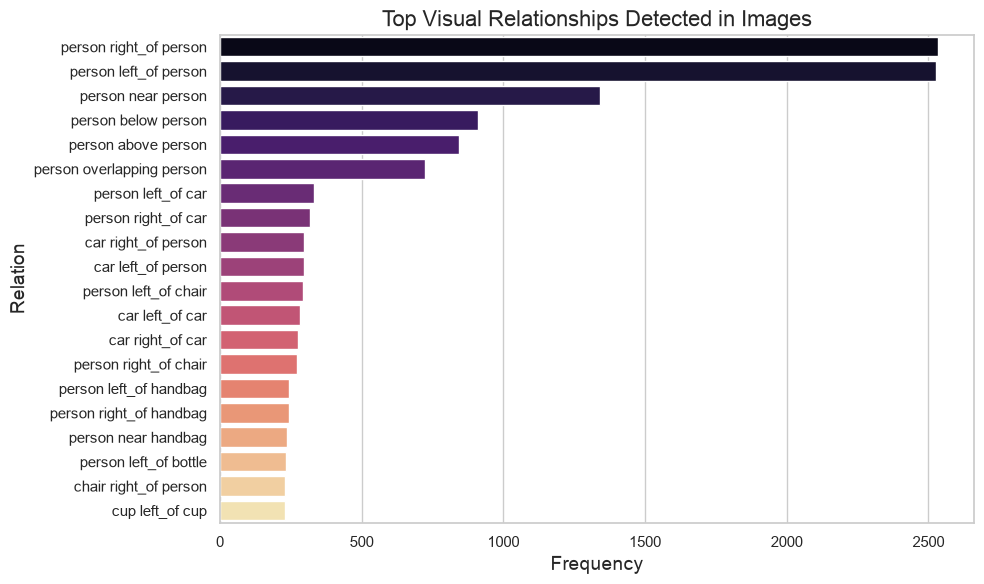

In [32]:
relation_counter = Counter()

for image_id_str, entry in lookup.items():
    image_id = int(image_id_str)
    if image_id in kb_image_ids:
        for rel in entry.get("relationships", []):
            subject = rel.get("subject", "")
            relation = rel.get("relation", "")
            obj = rel.get("object", "")
            pair = f"{subject} {relation} {obj}"
            relation_counter[pair] += 1

top_relations = relation_counter.most_common(20)
names = [k for k, _ in top_relations]
counts = [v for _, v in top_relations]

plt.figure(figsize=(10, 6))
sns.barplot(x=counts, y=names, palette="magma")
plt.title("Top Visual Relationships Detected in Images")
plt.xlabel("Frequency")
plt.ylabel("Relation")
plt.tight_layout()
plt.savefig("visual_relationships.png", dpi=300)
plt.show()

# 7. Data Visualization

### Object Co-Occurrence Matrix 

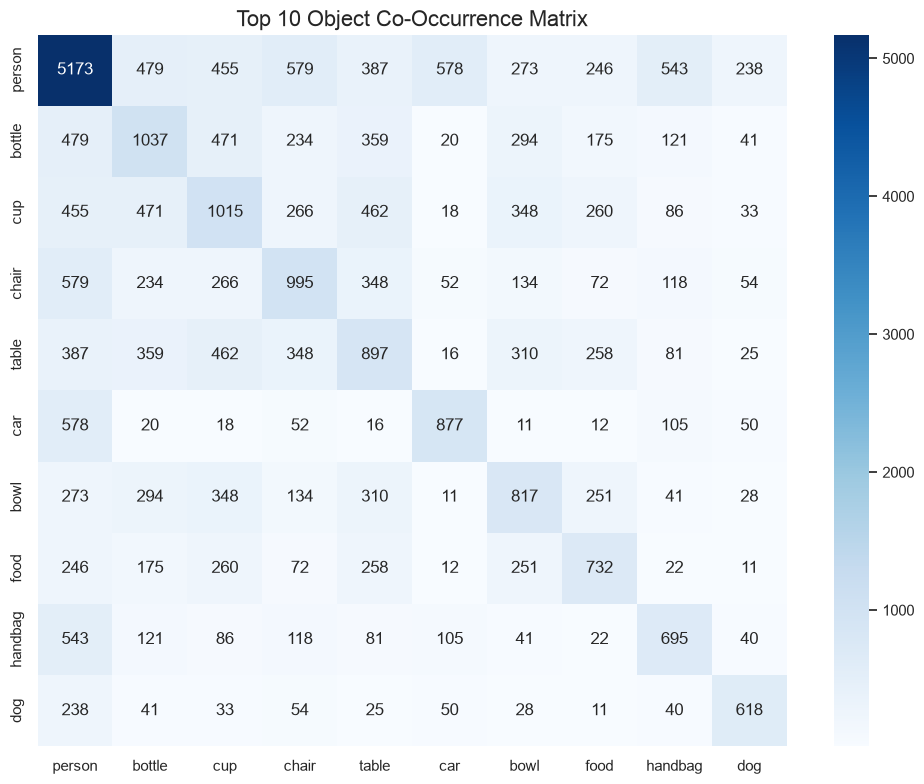

In [33]:
import pandas as pd
import numpy as np

# Map image_ids to list of object names present in that image
image_to_objects = {}
for image_id_str, entry in lookup.items():
    image_id = int(image_id_str)
    if image_id in kb_image_ids:
        image_to_objects[image_id] = set(entry.get("objects", []))

top_10_names = [obj for obj, _ in object_counter.most_common(10)]

# Build co-occurrence matrix
matrix_size = len(top_10_names)
co_occurrence = np.zeros((matrix_size, matrix_size))

for objs in image_to_objects.values():
    unique_objs = set(objs)
    for i, obj1 in enumerate(top_10_names):
        for j, obj2 in enumerate(top_10_names):
            if obj1 in unique_objs and obj2 in unique_objs:
                co_occurrence[i, j] += 1

# Plot Heatmap
plt.figure(figsize=(10, 8))
df_co = pd.DataFrame(co_occurrence, index=top_10_names, columns=top_10_names)
sns.heatmap(df_co, annot=True, fmt=".0f", cmap="Blues", cbar=True)
plt.title("Top 10 Object Co-Occurrence Matrix")
plt.savefig("object_cooccurrence_matrix.png", dpi=300)
plt.show()

### Caption Length Distribution Analysis 

### Caption Length Distribution Before vs After Preprocessing
We compare raw caption lengths with cleaned caption lengths to show how normalization changes the language distribution.

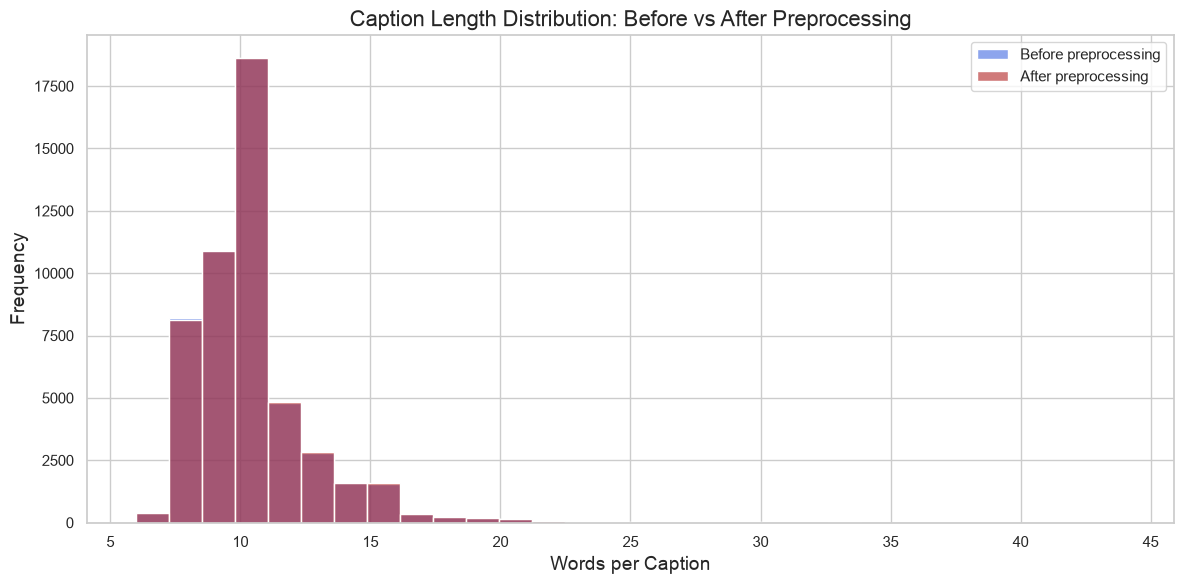

In [34]:
# Before vs After caption length distribution
before_lengths = [len(ann['caption'].split()) for ann in filtered_captions]
after_lengths = []

with open("../data/coco_rag_data/captions_kb.json", "r", encoding="utf-8") as f:
    caption_store = json.load(f)

for image_id, entry in caption_store.items():
    if int(image_id) in kb_image_ids:
        for cap in entry.get("caption_clean", []):
            after_lengths.append(len(cap.split()))

plt.figure(figsize=(12, 6))
sns.histplot(before_lengths, bins=30, color="royalblue", alpha=0.6, label="Before preprocessing", kde=False)
sns.histplot(after_lengths, bins=30, color="firebrick", alpha=0.6, label="After preprocessing", kde=False)

plt.title("Caption Length Distribution: Before vs After Preprocessing")
plt.xlabel("Words per Caption")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

## NOTE : they're the same cuz the caption preprocessing didnt affect the average
## caption length, but it did affect the vocabulary size and unique word count 

### Caption Length vs. Object Count per Image.

note : to show if there's a relation between if we words to captions will the the nb of objects increaces or decreases 

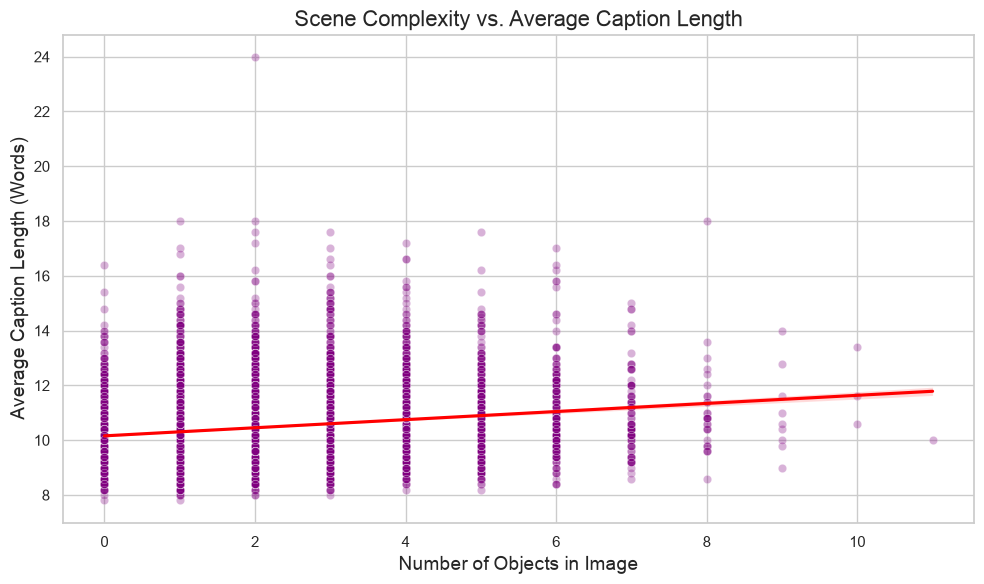

In [35]:
# Map image_id to its 5 or more caption lengths and its object count
image_to_len = {}
for ann in filtered_captions:
    img_id = ann['image_id']
    length = len(ann['caption'].split())
    image_to_len.setdefault(img_id, []).append(length)

# Create alignment lists for scatter plot (taking average caption length per image vs object count)
x_obj_counts = []
y_avg_cap_lengths = []

for img_id, lengths in image_to_len.items():
    if img_id in image_object_counts: # Ensure it has recorded objects
        x_obj_counts.append(image_object_counts[img_id])
        y_avg_cap_lengths.append(sum(lengths) / len(lengths))

# Plot Scatter Plot with Trendline
plt.figure(figsize=(10, 6))
sns.scatterplot(x=x_obj_counts, y=y_avg_cap_lengths, alpha=0.3, color='purple')
sns.regplot(x=x_obj_counts, y=y_avg_cap_lengths, scatter=False, color='red')
plt.title("Scene Complexity vs. Average Caption Length")
plt.xlabel("Number of Objects in Image")
plt.ylabel("Average Caption Length (Words)")
plt.savefig("complexity_vs_caption_length_scatter.png", dpi=300)
plt.show()

# 8. Export Summary Statistics CSV

In [36]:
# Create a quick summary dataframe for your report appendix
summary_data = {
    "Metric": [
        "Total Knowledge Base Images",
        "Total Reference Captions",
        "Total Detected Object Entries",
        "Average Words per Caption",
        "Unique Vocabulary Size",
        "Total Object Categories",
        "Average Objects per Image"
    ],
    "Value": [
        len(kb_image_ids),
        len(filtered_captions),
        sum(object_counter.values()),
        round(sum(caption_lengths) / len(caption_lengths), 2),
        f"{len(vocab_set):,}",
        len(object_counter),
        round(sum(objects_per_image_list) / len(objects_per_image_list), 2)
    ]
}

df_summary = pd.DataFrame(summary_data)
df_summary.to_csv("dataset_statistics_summary.csv", index=False)
print("Saved summary table to 'dataset_statistics_summary.csv'")
display(df_summary)

Saved summary table to 'dataset_statistics_summary.csv'


,Metric,Value
0,Total Knowledge Base Images,10000
1,Total Reference Captions,50029
2,Total Detected Object Entries,20419
3,Average Words per Caption,10.46
4,Unique Vocabulary Size,"13,658"
5,Total Object Categories,34
6,Average Objects per Image,2.04
